# Import Library

In [30]:
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import accuracy_score

## Read File

In [31]:
data=pd.read_csv('car data2.csv')


## Show DataFrame

In [32]:
data.head()

,Car_Name,Year,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Selling_Price
0,ritz,2014,5.59,27000.0,Petrol,Dealer,Manual,0.0,3.35
1,sx4,2013,9.54,43000.0,Diesel,Dealer,Manual,0.0,4.75
2,ciaz,2017,9.85,6900.0,Petrol,Dealer,Manual,0.0,7.25
3,wagon r,2011,4.15,5200.0,Petrol,Dealer,Manual,0.0,2.85
4,swift,2014,6.87,42450.0,Diesel,Dealer,Manual,0.0,4.60


In [33]:
data.shape

(301, 9)

In [34]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Present_Price  301 non-null    float64
 3   Kms_Driven     298 non-null    float64
 4   Fuel_Type      301 non-null    object 
 5   Seller_Type    301 non-null    object 
 6   Transmission   301 non-null    object 
 7   Owner          296 non-null    float64
 8   Selling_Price  301 non-null    float64
dtypes: float64(4), int64(1), object(4)
memory usage: 21.3+ KB


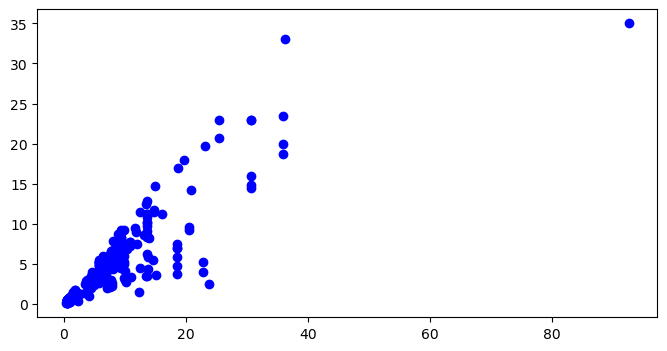

In [35]:
plt.figure(figsize=(8, 4))
plt.scatter(data['Present_Price'], data['Selling_Price'], color='b')

plt.show()

# PreProcessing

## Clean Missing Value
(Dropna)

In [36]:
data.isnull().sum()

Car_Name         0
Year             0
Present_Price    0
Kms_Driven       3
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            5
Selling_Price    0
dtype: int64

In [37]:
# Drops rows with any NaN values
data = data.dropna(how='any')

data.isnull().sum()

Car_Name         0
Year             0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
Selling_Price    0
dtype: int64

## Drop columns

In [38]:
data = data.drop(['Car_Name', 'Fuel_Type','Seller_Type','Transmission'], axis=1)
data.head()

,Year,Present_Price,Kms_Driven,Owner,Selling_Price
0,2014,5.59,27000.0,0.0,3.35
1,2013,9.54,43000.0,0.0,4.75
2,2017,9.85,6900.0,0.0,7.25
3,2011,4.15,5200.0,0.0,2.85
4,2014,6.87,42450.0,0.0,4.60


# Modeling 

## Split data

In [39]:
# X= All Feature except "Price"
x=data.drop(['Selling_Price' ], axis=1)

# y= feature "Price"
y=data['Selling_Price']

In [40]:
x_train,x_test, y_train,y_test = train_test_split(x,y,test_size=0.2, random_state=42)

## Train Model

In [41]:
model= LinearRegression()

model.fit(x_train,y_train)

LinearRegression()

## y_Prediction

In [42]:
y_predected =model.predict(x_test)
y_predected

array([ 4.98327666,  6.57274403,  2.26848245,  8.57748669,  6.48801402,
        2.64715209,  2.53486899,  4.21062185,  2.11929528,  6.93874094,
       10.14519652,  6.87993902,  1.35567582, 18.90266309,  1.43659612,
        4.79613352, 18.93453845,  0.78347831,  3.03697956,  7.55113769,
        7.73918188,  5.4724938 ,  4.77612778,  1.24570556,  5.97549013,
       16.66264113, 19.33953906,  0.73614004,  1.29905987, 14.89854984,
        5.78048274,  2.63389825,  4.67201031,  0.03752864,  5.21815705,
        2.18394516, 13.77683412,  3.90073469,  8.4583376 ,  4.32384169,
        6.95933515,  4.16338041,  1.19861233, 10.65457561,  7.67717993,
        0.17003152,  3.43729694,  0.17295353,  5.92120021,  2.12837315,
        4.80560998,  5.46418273,  1.78599121, 15.40973348, 14.47890379,
        1.79116018,  3.20782877,  2.36779786,  3.37466806])

## Evaluate Model

In [44]:
y_predected = y_predected.astype(int)
y_test = y_test.astype(int)

accuracy=accuracy_score( y_predected, y_test)
accuracy

0.3220338983050847

## visualize the regression model

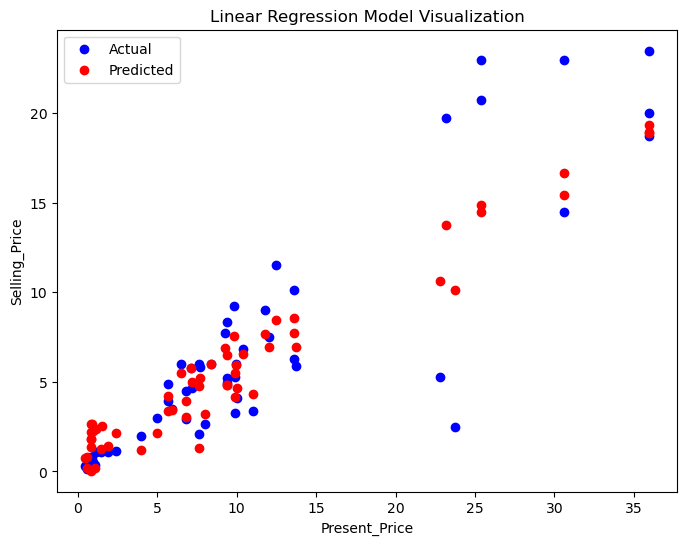

In [55]:

# Scatter plot of one feature against the target
plt.figure(figsize=(8, 6))
plt.scatter(x_test['Present_Price'], y_test, color='blue', label='Actual')

# Plot the regression line (predicted values)
plt.scatter(x_test['Present_Price'], y_predected, color='red', label='Predicted')

plt.xlabel('Present_Price')
plt.ylabel('Selling_Price')
plt.title('Linear Regression Model Visualization')
plt.legend()
plt.show()

## Plotting Regression Line for a Single Feature

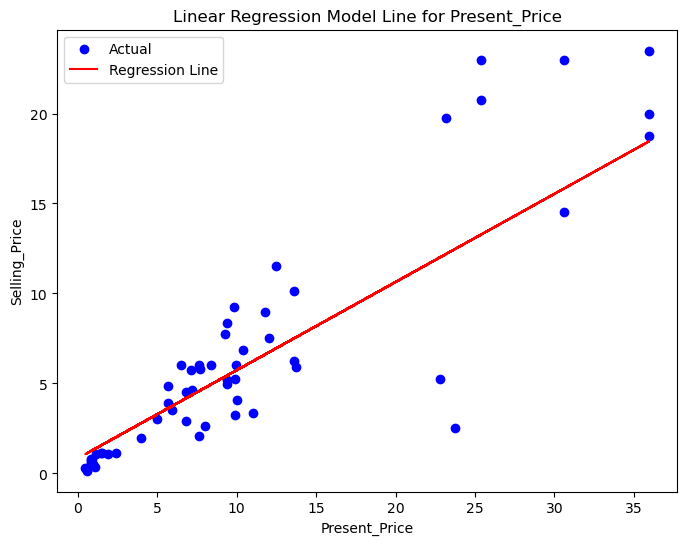

In [58]:
# Train a simple linear regression model using only 'Present_Price'
x_train_simple = x_train[['Present_Price']]  # Only one feature
x_test_simple = x_test[['Present_Price']]

# Predictions for the simple linear regression
y_pred_simple = model.predict(x_test_simple)



# Scatter plot and regression line
plt.figure(figsize=(8, 6))

plt.scatter(x_test['Present_Price'], y_test, color='blue', label='Actual')
plt.plot(x_test['Present_Price'], y_pred_simple, color='red', label='Regression Line')

plt.xlabel('Present_Price')
plt.ylabel('Selling_Price')
plt.title('Linear Regression Model Line for Present_Price')
plt.legend()
plt.show()